# 02 - Vectorization & Naive Bayes & Logistic Regression (B)

In [32]:
import sys
sys.path.append("..")

from src.config import *
from src.data import load_split
from src.cleaning import clean_text
from src.evaluate import evaluate, save_results

## Preparation

In [42]:
import pandas as pd
from src.config import *
from src.model import build_pipeline

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score
from matplotlib import pyplot as plt

METRICS_CSV = RESULTS / "metrics_B.csv"
from sklearn.naive_bayes import MultinomialNB, ComplementNB




## Loading cleaned data

In [43]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
val = pd.read_csv(PROCESSED_DIR / "validation.csv")

train["text_clean"] = train["text_clean"].fillna("")
val["text_clean"] = val["text_clean"].fillna("")

X_train, y_train = train["text_clean"], train["label"]
X_val, y_val = val["text_clean"], val["label"]

print("train :", X_train.shape, "| val :", X_val.shape)

train : (2859,) | val : (955,)


# 1. Vectorization

## 1.1 create the TF-IDF vectorizer (the object that transforms text into numbers)

In [35]:
TOKEN_PATTERN = r"[\w']+|[^\w\s]"
vec = TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=False)
M_train = vec.fit_transform(X_train)     # fit to the train ONLY
M_val = vec.transform(X_val)

print("Matrice train :", M_train.shape)
print("Matrice val   :", M_val.shape)
print("Part de cases non nulles :", round(M_train.nnz / (M_train.shape[0] * M_train.shape[1]) * 100, 3), "%")

Matrice train : (2859, 9670)
Matrice val   : (955, 9670)
Part de cases non nulles : 0.148 %


## 1.2 Comparison of configurations
Why Logistic Regression? To compare the cleaning versions and vectorizer settings, we needed one fixed, simple model, so that any change in score comes from the preprocessing and not from the model. Logistic Regression is a strong baseline for text classification on sparse TF-IDF features, it is fast enough to test many configurations, and it is interpretable: it learns one weight per word, which lets us show the words that push towards irony or non-irony. It also serves as the reference against which the other models are compared.

,n_features,accuracy_val,f1_macro_val,f1_macro_cv_train
"BoW words (1,1)",9670,0.6230,0.6227,0.6205
"TF-IDF words (1,1)",9670,0.6325,0.6323,0.6126
"TF-IDF words (1,1) + sublinear_tf",9670,0.6220,0.6217,0.6152
"TF-IDF words (1,2)",41106,0.6283,0.6281,0.6142
"TF-IDF words (1,2) + min_df=2",6976,0.6346,0.6345,0.6192
"TF-IDF words (1,2) + min_df=2 + sublinear_tf",6976,0.6283,0.6281,0.6184
"TF-IDF char_wb (2,5)",83517,0.6272,0.6272,0.6252
"TF-IDF char_wb (2,5) + sublinear_tf",83517,0.6178,0.6178,0.6265
"TF-IDF char_wb (2,5) + min_df=2 + sublinear_tf",32923,0.6199,0.6196,0.6234


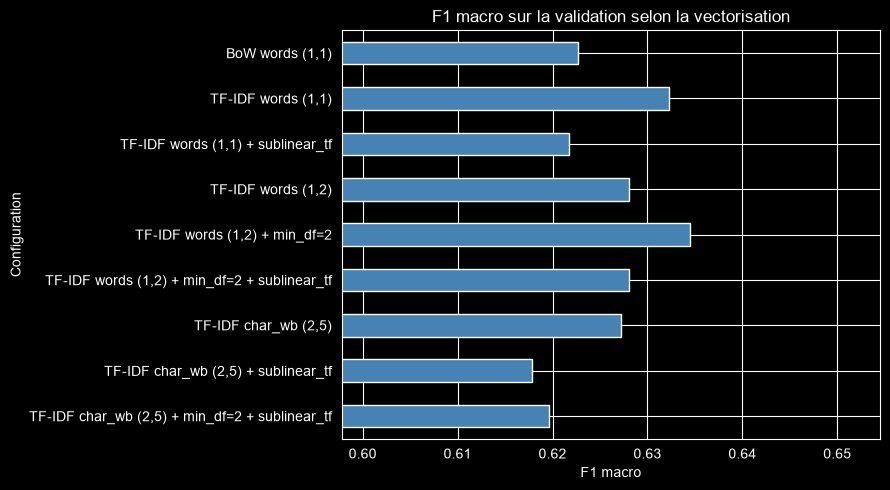

In [36]:
def faire_pipeline(vectorizer):
    return Pipeline([
        ("tfidf", vectorizer),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

words = dict(token_pattern=TOKEN_PATTERN, lowercase=False)
chars = dict(analyzer="char_wb", ngram_range=(2, 5), lowercase=False)

configs = {
    "BoW words (1,1)": CountVectorizer(**words),
    "TF-IDF words (1,1)": TfidfVectorizer(**words),
    "TF-IDF words (1,1) + sublinear_tf": TfidfVectorizer(**words, sublinear_tf=True),
    "TF-IDF words (1,2)": TfidfVectorizer(**words, ngram_range=(1, 2)),
    "TF-IDF words (1,2) + min_df=2": TfidfVectorizer(**words, ngram_range=(1, 2), min_df=2),
    "TF-IDF words (1,2) + min_df=2 + sublinear_tf": TfidfVectorizer(**words, ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    "TF-IDF char_wb (2,5)": TfidfVectorizer(**chars),
    "TF-IDF char_wb (2,5) + sublinear_tf": TfidfVectorizer(**chars, sublinear_tf=True),
    "TF-IDF char_wb (2,5) + min_df=2 + sublinear_tf": TfidfVectorizer(**chars, min_df=2, sublinear_tf=True),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def tester(vectorizer):
    modele = faire_pipeline(vectorizer)
    modele.fit(X_train, y_train)
    pred = modele.predict(X_val)

    cv_f1 = cross_val_score(faire_pipeline(vectorizer), X_train, y_train, cv=cv, scoring="f1_macro").mean()

    return {
        "n_features": len(modele.named_steps["tfidf"].get_feature_names_out()),
        "accuracy_val": accuracy_score(y_val, pred),
        "f1_macro_val": f1_score(y_val, pred, average="macro"),
        "f1_macro_cv_train": cv_f1,
    }
resultats = pd.DataFrame({nom: tester(v) for nom, v in configs.items()}).T
resultats["n_features"] = resultats["n_features"].astype(int)
resultats = resultats.round(4)
display(resultats)

plt.figure(figsize=(9, 5))
resultats["f1_macro_val"].iloc[::-1].plot(kind="barh", color="steelblue")
plt.title("F1 macro sur la validation selon la vectorisation")
plt.xlabel("F1 macro")
plt.ylabel("Configuration")
plt.xlim(resultats["f1_macro_val"].min() - 0.02, resultats["f1_macro_val"].max() + 0.02)
plt.tight_layout()
plt.show()

We choose TF-IDF mots (1,2) + min_df=2 because it achieves the highest F1-macro score (approximately 0.635).
It provides the best balance between performance and capturing useful information through both unigrams and bigrams.

## 1.3 Configuration retenue

In [37]:
#Finds the name of the configuration with the highest f1_macro_val in the results table
meilleure = resultats["f1_macro_val"].idxmax()
print("Configuration retenue :", meilleure)
print(resultats.loc[meilleure])
print()
print(configs[meilleure].get_params(deep=False))

Configuration retenue : TF-IDF words (1,2) + min_df=2
n_features           6976.0000
accuracy_val            0.6346
f1_macro_val            0.6345
f1_macro_cv_train       0.6192
Name: TF-IDF words (1,2) + min_df=2, dtype: float64

{'analyzer': 'word', 'binary': False, 'decode_error': 'strict', 'dtype': <class 'numpy.float64'>, 'encoding': 'utf-8', 'input': 'content', 'lowercase': False, 'max_df': 1.0, 'max_features': None, 'min_df': 2, 'ngram_range': (1, 2), 'norm': 'l2', 'preprocessor': None, 'smooth_idf': True, 'stop_words': None, 'strip_accents': None, 'sublinear_tf': False, 'token_pattern': "[\\w']+|[^\\w\\s]", 'tokenizer': None, 'use_idf': True, 'vocabulary': None}


## Verification

In [38]:
modele_final = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
modele_final.fit(X_train, y_train)
pred = modele_final.predict(X_val)

print("F1 macro (validation) :", round(f1_score(y_val, pred, average="macro"), 4))
print("Table value           :", resultats.loc[meilleure, "f1_macro_val"])

F1 macro (validation) : 0.6345
Table value           : 0.6345


# 2. Naive Bayes

## 2.1 Tuning alpha (smoothing) on the validation set

,model,alpha,accuracy_val,f1_macro_val,f1_macro_cv_train
0,MultinomialNB,0.01,0.6325,0.6324,0.6014
1,MultinomialNB,0.05,0.6304,0.6304,0.6009
2,MultinomialNB,0.10,0.6377,0.6377,0.6062
3,MultinomialNB,0.30,0.6377,0.6377,0.6105
4,MultinomialNB,0.50,0.6366,0.6366,0.6099
5,MultinomialNB,1.00,0.6325,0.6324,0.6194
6,MultinomialNB,2.00,0.6314,0.6314,0.6209
7,ComplementNB,0.01,0.6304,0.6303,0.6002
8,ComplementNB,0.05,0.6314,0.6314,0.6059
9,ComplementNB,0.10,0.6325,0.6325,0.6062


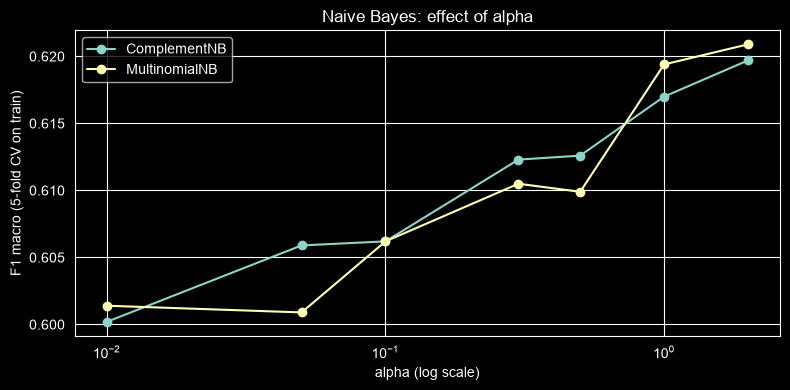

In [40]:
alphas = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0]
rows = []
for nom, Model in [("MultinomialNB",MultinomialNB ),("ComplementNB",ComplementNB)]:
    for alpha in alphas:
        m= build_pipeline(Model(alpha=alpha))
        m.fit(X_train, y_train)
        pred = m.predict(X_val)

        cv_f1=cross_val_score(m, X_train, y_train, cv=cv, scoring="f1_macro").mean()

        rows.append({
            "model" : nom,
            "alpha" : alpha,
            "accuracy_val" : accuracy_score(y_val, pred),
            "f1_macro_val" : f1_score(y_val, pred, average="macro"),
            "f1_macro_cv_train" : cv_f1,
        })
nb_results= pd.DataFrame(rows).round(4)
display(nb_results)

plt.figure(figsize=(8, 4))
for nom, groupe in nb_results.groupby("model"):
    plt.plot(groupe["alpha"], groupe["f1_macro_cv_train"], marker="o", label=nom)
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("F1 macro (5-fold CV on train)")
plt.title("Naive Bayes: effect of alpha")
plt.legend()
plt.tight_layout()
plt.show()

## 2.2 Best Naitive Bayes

model                MultinomialNB
alpha                          2.0
accuracy_val                0.6314
f1_macro_val                0.6314
f1_macro_cv_train           0.6209
Name: 6, dtype: object
---MultinomialNB---
              precision    recall  f1-score   support

   non_irony      0.664     0.597     0.629       499
       irony      0.603     0.669     0.634       456

    accuracy                          0.631       955
   macro avg      0.633     0.633     0.631       955
weighted avg      0.635     0.631     0.631       955



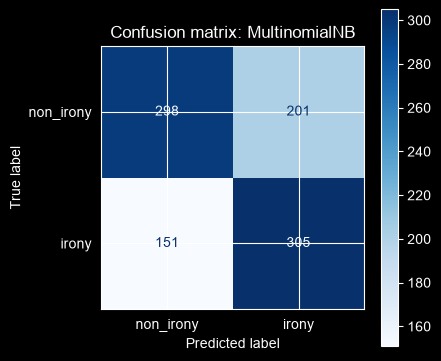

In [41]:
best = nb_results.loc[nb_results["f1_macro_cv_train"].idxmax()]   # pick by CV on train
print(best)
Modele_best= MultinomialNB if best["model"] == "MultinomialNB" else ComplementNB
nb_final= build_pipeline(Modele_best(alpha=best["alpha"]))
nb_final.fit(X_train, y_train)
pred_nb= nb_final.predict(X_val)

nb_name = type(nb_final.named_steps["clf"]).__name__
nb_metrics = evaluate(nb_name, y_val, pred_nb)
save_results(nb_metrics, METRICS_CSV, alpha=best["alpha"])